# Saúde em Foco — Análise de dados do ABC Paulista

**FIAP | Global Solution 2026.2 — CitizenTech: Data Science, Inovação e Tecnologia**

| Campo | Informação |
|---|---|
| **Turma** | `[1TSCO B]` |
| **Projeto** | Saúde em Foco |
| **Grupo** | `[Data Health]` |

**Integrantes (ordem alfabética) — nome completo e RM:**

| Nome completo | RM | 
|---|---|
| `Amanda Silva dos Santos` | `RM573167` | 
| `Cauê Almiron` | `RM571945` |

## 1. Problema, hipóteses e perguntas da análise

**Problema e território.** O ABC Paulista reúne sete municípios — Diadema, Mauá, Ribeirão Pires, Rio Grande da Serra, Santo André, São Bernardo do Campo e São Caetano do Sul — com cerca de 2,7 milhões de habitantes (Censo 2022). Com dados abertos, não é simples saber se a presença de serviços de saúde acompanha o tamanho da população de cada município. A plataforma **Saúde em Foco** propõe tornar essa leitura visível para cidadãos e gestores. Esta análise é o primeiro passo: dimensiona a distribuição dos estabelecimentos cadastrados no CNES em relação à população e delimita o que os dados atuais permitem — e não permitem — afirmar.

**Hipóteses retomadas da proposta executiva (1ª parte):**

| Hipótese | Enunciado |
|---|---|
| **H1** | A quantidade de estabelecimentos de saúde cadastrados varia entre os municípios do ABC. |
| **H2** | A quantidade por habitante também difere entre os municípios, ou seja, a distribuição não é proporcional à população. |
| **H3** | Há associação entre o tamanho da população e a quantidade de registros CNES. |
| **H4** | Existe relação entre a disponibilidade de estabelecimentos e a produção de serviços de saúde. |

**Perguntas que a análise pretende responder:**

1. **P1.** Quantos registros CNES existem em cada município e como eles se distribuem em relação à população? *(H1, H2)*
2. **P2.** Qual município está mais distante da média regional e esse resultado é um valor atípico (*outlier*)? *(H2)*
3. **P3.** O tamanho da população se associa à quantidade de registros? A associação resiste à retirada do município atípico? *(H3)*
4. **P4.** Os resultados mudam se considerarmos apenas registros sem motivo de desabilitação preenchido? *(robustez de H1 a H3)*
5. **P5.** O que o cadastro isolado **não** consegue responder e que dados faltam para a solução? *(H4)*

**Mapa da análise:**

| Etapa | Seção |
|---|---|
| Fontes e variáveis | 2 |
| Carga, estado inicial, limpeza e minimização de dados pessoais | 3 a 6 |
| Integração CNES × IBGE (técnica escolhida nº 2) e indicadores | 7 |
| Estatística descritiva e comparação entre municípios | 8 |
| *Outliers* e normalização de escala | 9 |
| Sensibilidade à situação cadastral | 10 |
| Correlação (técnica escolhida nº 1) | 11 |
| Visualizações | 12 |
| Conclusões, limitações e uso responsável | 13 a 15 |

## 2. Fontes e descrição dos dados

Todas as bases são **públicas e reais**. Não foram usados dados simulados.

| Base | Órgão responsável | Fonte | Período de referência |
|---|---|---|---|
| **CNES — Estabelecimentos de saúde** | Ministério da Saúde (DATASUS) | [Portal de Dados Abertos do SUS](https://dadosabertos.saude.gov.br/dataset/cnes-cadastro-nacional-de-estabelecimentos-de-saude), arquivo `cnes_estabelecimentos_json.zip` | Arquivo gerado em **14/11/2026** (data do arquivo dentro do ZIP). O arquivo não informa a competência do cadastro; ver seção 15. |
| **População residente** | IBGE | [SIDRA, tabela 4709](https://sidra.ibge.gov.br/tabela/4709), variável 93 (Censo Demográfico) | **2022** |

No processamento do arquivo bruto foram lidos **642.608 registros** de todo o país, dos quais **6.290** pertencem aos sete municípios do ABC.

**Principais variáveis utilizadas:**

| Variável | Descrição (conforme o dicionário do CNES e do SIDRA) | Uso na análise |
|---|---|---|
| `CO_CNES` | Código do estabelecimento no CNES | Contagem de registros (identificador único) |
| `CO_IBGE` | Código do município com 6 dígitos (o IBGE usa 7) | Chave de integração com o Censo |
| `DS_ESFERA_ADMINISTRATIVA` | Esfera administrativa informada no cadastro (municipal ou estadual) | Caracterização; **não** equivale a "rede pública" |
| `TP_GESTAO` | Tipo de gestão (M = municipal, E = estadual) | Conferência da esfera administrativa |
| `CO_NATUREZA_JUR` | Código da natureza jurídica | Apenas descrição; não foi usada para classificar público/privado |
| `CO_AMBULATORIAL_SUS` | Indica atendimento ambulatorial SUS (SIM/NAO) | Indicador específico de atendimento ambulatorial SUS |
| `CO_MOTIVO_DESAB` | Código do motivo de desabilitação | Análise de sensibilidade (seção 10) |
| `populacao_2022` | População residente no município (Censo 2022) | Denominador dos indicadores por habitante |

## 3. Preparação do ambiente e carga dos dados

O arquivo bruto do CNES tem cerca de 650 MB descompactado e contém identificadores de estabelecimentos (CNPJ, telefone, e-mail e endereço). Por isso o notebook:

1. lê o JSON **em fluxo** (sem carregar tudo na memória) e filtra os sete municípios;
2. **remove os campos de identificação** antes de salvar qualquer arquivo (seção 6);
3. grava o resultado em `dados/tratados/cnes_abc_minimizado.csv`.

Quem receber somente o ZIP de entrega reproduz toda a análise a partir desse CSV. Quem tiver o arquivo bruto em `dados/brutos/` reconstrói o CSV a partir dele.

In [1]:
from pathlib import Path
from zipfile import ZipFile
import io
import json
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

PASTA_DADOS = Path("dados")
PASTA_BRUTOS = PASTA_DADOS / "brutos"
PASTA_TRATADOS = PASTA_DADOS / "tratados"
PASTA_BRUTOS.mkdir(parents=True, exist_ok=True)
PASTA_TRATADOS.mkdir(parents=True, exist_ok=True)

print("Pandas", pd.__version__, "| NumPy", np.__version__)

Pandas 2.0.3 | NumPy 1.24.3


In [2]:
# Tabela de referência com os sete municípios do ABC Paulista.
municipios_abc = pd.DataFrame({
    "codigo_ibge": ["3513801", "3529401", "3543303", "3544103", "3547809", "3548708", "3548807"],
    "municipio": ["Diadema", "Mauá", "Ribeirão Pires", "Rio Grande da Serra",
                  "Santo André", "São Bernardo do Campo", "São Caetano do Sul"],
    "uf": ["SP"] * 7
})
# O CNES usa o código municipal de 6 dígitos (sem o dígito verificador do IBGE).
municipios_abc["codigo_cnes_6"] = municipios_abc["codigo_ibge"].str[:6]
municipios_abc

,codigo_ibge,municipio,uf,codigo_cnes_6
0,3513801,Diadema,SP,351380
1,3529401,Mauá,SP,352940
2,3543303,Ribeirão Pires,SP,354330
3,3544103,Rio Grande da Serra,SP,354410
4,3547809,Santo André,SP,354780
5,3548708,São Bernardo do Campo,SP,354870
6,3548807,São Caetano do Sul,SP,354880


### 3.1 População — IBGE/SIDRA 4709 (Censo 2022)

Se o CSV da população existir em `dados/tratados/`, ele é usado. Caso contrário, a população é consultada na API do SIDRA.

In [3]:
arq_populacao = PASTA_TRATADOS / "populacao_abc_censo_2022.csv"

if arq_populacao.exists():
    populacao_ibge = pd.read_csv(arq_populacao, dtype={"codigo_ibge": str}, encoding="utf-8-sig")
    print("População carregada de:", arq_populacao)
else:
    url_sidra = ("https://apisidra.ibge.gov.br/values/t/4709/"
                 "n6/3513801,3529401,3543303,3544103,3547809,3548708,3548807/v/93/p/2022")
    with urllib.request.urlopen(url_sidra, timeout=60) as resposta:
        dados_sidra = json.load(resposta)
    populacao_ibge = pd.DataFrame(dados_sidra[1:]).rename(columns={
        "D1C": "codigo_ibge", "D1N": "municipio_ibge", "V": "populacao_2022"})
    populacao_ibge = populacao_ibge[["codigo_ibge", "municipio_ibge", "populacao_2022"]]
    populacao_ibge.to_csv(arq_populacao, index=False, encoding="utf-8-sig")
    print("População consultada na API do SIDRA e salva em:", arq_populacao)

populacao_ibge["codigo_ibge"] = populacao_ibge["codigo_ibge"].astype(str)
populacao_ibge["populacao_2022"] = pd.to_numeric(populacao_ibge["populacao_2022"], errors="coerce")
populacao_ibge = populacao_ibge[["codigo_ibge", "municipio_ibge", "populacao_2022"]].drop_duplicates()

# Conferência: esperamos exatamente os sete municípios, cada um com população.
conferencia_ibge = municipios_abc.merge(populacao_ibge, on="codigo_ibge", how="left", validate="one_to_one")
assert len(conferencia_ibge) == 7, "A base de população não tem os sete municípios."
assert conferencia_ibge["populacao_2022"].notna().all(), "Há município sem população."
print("População total do ABC (Censo 2022):", f"{int(conferencia_ibge['populacao_2022'].sum()):,}".replace(",", "."))
conferencia_ibge

População carregada de: dados\tratados\populacao_abc_censo_2022.csv
População total do ABC (Censo 2022): 2.696.530


,codigo_ibge,municipio,uf,codigo_cnes_6,municipio_ibge,populacao_2022
0,3513801,Diadema,SP,351380,Diadema (SP),393237
1,3529401,Mauá,SP,352940,Mauá (SP),418261
2,3543303,Ribeirão Pires,SP,354330,Ribeirão Pires (SP),115559
3,3544103,Rio Grande da Serra,SP,354410,Rio Grande da Serra (SP),44170
4,3547809,Santo André,SP,354780,Santo André (SP),748919
5,3548708,São Bernardo do Campo,SP,354870,São Bernardo do Campo (SP),810729
6,3548807,São Caetano do Sul,SP,354880,São Caetano do Sul (SP),165655


### 3.2 Registros do CNES

A célula abaixo escolhe a origem dos dados: o **arquivo bruto** (se existir em `dados/brutos/` ou na pasta do notebook) ou o **CSV minimizado** já gerado. O leitor em fluxo usa apenas a biblioteca padrão do Python.

In [4]:
def iter_json_array(arquivo_binario, tamanho_bloco=4 * 1024 * 1024):
    # Lê um JSON que é uma lista de objetos, um objeto por vez, sem carregar o arquivo inteiro.
    leitor = io.TextIOWrapper(arquivo_binario, encoding="utf-8")
    decodificador = json.JSONDecoder()
    buffer, pos, iniciou, terminou = "", 0, False, False
    while not terminou:
        bloco = leitor.read(tamanho_bloco)
        terminou = not bloco
        buffer = buffer[pos:] + bloco
        pos = 0
        if not iniciou:
            buffer = buffer.lstrip()
            if not buffer:
                continue
            if buffer[0] != "[":
                raise ValueError("O JSON do CNES deveria ser uma lista de registros.")
            buffer, iniciou = buffer[1:], True
        while True:
            while pos < len(buffer) and buffer[pos] in " \r\n\t,":
                pos += 1
            if pos >= len(buffer) or buffer[pos] == "]":
                break
            try:
                objeto, fim_objeto = decodificador.raw_decode(buffer, pos)
            except json.JSONDecodeError:
                if terminou:
                    raise
                break  # objeto incompleto: lê o próximo bloco
            yield objeto
            pos = fim_objeto


ARQ_CNES_MINIMIZADO = PASTA_TRATADOS / "cnes_abc_minimizado.csv"
codigos_abc_6 = set(municipios_abc["codigo_cnes_6"])

candidatos_zip = [PASTA_BRUTOS / "cnes_estabelecimentos_json.zip", Path("cnes_estabelecimentos_json.zip")]
arquivo_zip_cnes = next((p for p in candidatos_zip if p.exists()), None)

if arquivo_zip_cnes is not None:
    FONTE_CNES = f"arquivo bruto: {arquivo_zip_cnes}"
    with ZipFile(arquivo_zip_cnes) as z:
        entrada = [i for i in z.infolist() if i.filename.lower().endswith(".json")][0]
        print("JSON dentro do ZIP:", entrada.filename, "| data do arquivo: %04d-%02d-%02d" % entrada.date_time[:3])
        lidos, registros_abc = 0, []
        with z.open(entrada) as f:
            for registro in iter_json_array(f):
                lidos += 1
                if str(registro.get("CO_IBGE", "")).strip() in codigos_abc_6:
                    registros_abc.append(registro)
    cnes_bruto = pd.DataFrame(registros_abc)
    print(f"Registros lidos no país: {lidos:,}".replace(",", "."), "| no ABC:", len(cnes_bruto))
elif ARQ_CNES_MINIMIZADO.exists():
    FONTE_CNES = f"CSV minimizado: {ARQ_CNES_MINIMIZADO}"
    cnes_bruto = pd.read_csv(ARQ_CNES_MINIMIZADO, dtype=str, keep_default_na=False, encoding="utf-8-sig")
else:
    raise FileNotFoundError(
        "Coloque dados/tratados/cnes_abc_minimizado.csv (incluído no ZIP de entrega) "
        "ou o arquivo cnes_estabelecimentos_json.zip em dados/brutos/.")

print("Fonte usada:", FONTE_CNES)
print("Dimensão dos dados carregados:", cnes_bruto.shape)

JSON dentro do ZIP: cnes_estabelecimentos.json | data do arquivo: 2026-11-14
Registros lidos no país: 642.608 | no ABC: 6290
Fonte usada: arquivo bruto: dados\brutos\cnes_estabelecimentos_json.zip
Dimensão dos dados carregados: (6290, 36)


## 4. Estado inicial dos dados

Antes de qualquer tratamento, registramos como os dados chegam: dimensão, tipos, valores vazios e duplicidades. Um ponto de atenção: **campos vazios chegam como texto vazio (`""`), e não como valor ausente**. Isso faz `.notna()` contar todos os registros como preenchidos.

In [5]:
CAMPOS_AUDITADOS = ["CO_MOTIVO_DESAB", "DS_ESFERA_ADMINISTRATIVA", "DS_NATUREZA_ORGANIZACAO",
                    "CO_NATUREZA_JUR", "CO_ATIVIDADE", "CO_AMBULATORIAL_SUS", "TP_GESTAO"]
CAMPOS_AUDITADOS = [c for c in CAMPOS_AUDITADOS if c in cnes_bruto.columns]

estado_inicial = pd.DataFrame({
    "campo": CAMPOS_AUDITADOS,
    "preenchidos_segundo_notna": [int(cnes_bruto[c].notna().sum()) for c in CAMPOS_AUDITADOS],
    "vazios_como_texto": [int(cnes_bruto[c].astype("string").str.strip().eq("").sum()) for c in CAMPOS_AUDITADOS],
})
estado_inicial["preenchidos_reais"] = len(cnes_bruto) - estado_inicial["vazios_como_texto"]

print("Registros:", len(cnes_bruto), "| Colunas:", cnes_bruto.shape[1])
print("Códigos CNES únicos:", cnes_bruto["CO_CNES"].nunique())
print("Duplicados por CO_CNES:", int(cnes_bruto.duplicated(subset=["CO_CNES"]).sum()))
estado_inicial

Registros: 6290 | Colunas: 36
Códigos CNES únicos: 6290
Duplicados por CO_CNES: 0


,campo,preenchidos_segundo_notna,vazios_como_texto,preenchidos_reais
0,CO_MOTIVO_DESAB,6290,4627,1663
1,DS_ESFERA_ADMINISTRATIVA,6290,0,6290
2,DS_NATUREZA_ORGANIZACAO,6290,6289,1
3,CO_NATUREZA_JUR,6290,0,6290
4,CO_ATIVIDADE,6290,0,6290
5,CO_AMBULATORIAL_SUS,6290,0,6290
6,TP_GESTAO,6290,0,6290


**Leitura:** nenhum campo aparece como ausente para o pandas, mas dois deles (`CO_MOTIVO_DESAB` e `DS_NATUREZA_ORGANIZACAO`) têm quase todos os valores vazios, disfarçados de texto. O caso mais relevante é `CO_MOTIVO_DESAB`: pelo critério `notna()` todos os registros pareceriam ter motivo; na realidade, a maior parte está em branco. Se esse erro não fosse tratado, a análise de situação cadastral (seção 10) ficaria incorreta.

## 5. Limpeza e padronização

Tratamentos aplicados e a justificativa de cada um:

| Tratamento | Por quê |
|---|---|
| Remover espaços e converter texto vazio em valor ausente (`NA`) | Para que `.notna()`, contagens e *crosstabs* reflitam a realidade (ex.: `CO_ESFERA_ADMINISTRATIVA` vem como `"M "`, com espaço) |
| Converter `ST_*` (indicadores 0/1) para número | Tipo coerente com o conteúdo |
| Manter códigos (`CO_*`) como texto | Preserva zeros à esquerda (ex.: atividade `04`) |
| Padronizar categorias em maiúsculas | Evita duplicar categorias por diferença de grafia |
| Completar `CO_IBGE` com 6 dígitos e relacionar ao município | Chave de integração com o IBGE |
| Verificar duplicados por `CO_CNES` | Evita contar o mesmo estabelecimento duas vezes |
| **Não** remover registros com motivo de desabilitação | Sem confirmar o significado no dicionário, a exclusão seria arbitrária; tratamos como análise de sensibilidade (seção 10) |

In [6]:
cnes_abc = cnes_bruto.copy()

# 1. Texto: remove espaços e transforma vazio em valor ausente.
for coluna in cnes_abc.columns:
    cnes_abc[coluna] = cnes_abc[coluna].astype("string").str.strip().replace("", pd.NA)

# 2. Tipos: indicadores ST_* viram número.
for coluna in [c for c in cnes_abc.columns if c.startswith("ST_")]:
    cnes_abc[coluna] = pd.to_numeric(cnes_abc[coluna], errors="coerce")

# 3. Padronização de categorias e do código municipal.
for coluna in ["DS_ESFERA_ADMINISTRATIVA", "CO_AMBULATORIAL_SUS", "TP_GESTAO"]:
    cnes_abc[coluna] = cnes_abc[coluna].str.upper()
cnes_abc["CO_IBGE"] = cnes_abc["CO_IBGE"].str.zfill(6)

# 4. Duplicados por estabelecimento.
duplicados_removidos = int(cnes_abc.duplicated(subset=["CO_CNES"]).sum())
cnes_abc = cnes_abc.drop_duplicates(subset=["CO_CNES"]).reset_index(drop=True)

# 5. Relaciona cada registro ao município (código de 6 dígitos -> município).
cnes_abc = cnes_abc.drop(columns=["codigo_ibge", "codigo_cnes_6", "municipio"], errors="ignore").merge(
    municipios_abc[["codigo_ibge", "codigo_cnes_6", "municipio"]],
    left_on="CO_IBGE", right_on="codigo_cnes_6", how="left", validate="many_to_one")
assert cnes_abc["municipio"].notna().all(), "Há registro sem município."

print("Duplicados removidos:", duplicados_removidos)
print("Registros após a limpeza:", len(cnes_abc))

antes_depois = estado_inicial[["campo", "preenchidos_segundo_notna"]].rename(
    columns={"preenchidos_segundo_notna": "preenchidos_antes"})
antes_depois["preenchidos_depois"] = [int(cnes_abc[c].notna().sum()) for c in antes_depois["campo"]]
antes_depois["ausentes_depois"] = len(cnes_abc) - antes_depois["preenchidos_depois"]
antes_depois["percentual_preenchido_depois"] = (antes_depois["preenchidos_depois"] / len(cnes_abc) * 100).round(2)
antes_depois

Duplicados removidos: 0
Registros após a limpeza: 6290


,campo,preenchidos_antes,preenchidos_depois,ausentes_depois,percentual_preenchido_depois
0,CO_MOTIVO_DESAB,6290,1663,4627,26.44
1,DS_ESFERA_ADMINISTRATIVA,6290,6290,0,100.00
2,DS_NATUREZA_ORGANIZACAO,6290,1,6289,0.02
3,CO_NATUREZA_JUR,6290,6290,0,100.00
4,CO_ATIVIDADE,6290,6290,0,100.00
5,CO_AMBULATORIAL_SUS,6290,6290,0,100.00
6,TP_GESTAO,6290,6290,0,100.00


**Resultado:** o quadro compara o que o `notna()` indicava antes (todos preenchidos) com o que existe de fato depois da limpeza. `CO_MOTIVO_DESAB` está preenchido em **1.663** dos 6.290 registros (26,4%) e em branco nos demais; `DS_NATUREZA_ORGANIZACAO` está quase todo vazio, e por isso não serve para classificar a rede em pública ou privada. Não há duplicados por `CO_CNES`.

## 6. Minimização de dados pessoais e exportação (LGPD)

O CNES cadastra estabelecimentos, e alguns são pessoas físicas ou empresários individuais (por exemplo, consultórios). Telefone, e-mail, CNPJ, razão social, nome fantasia e endereço podem, nesses casos, identificar uma pessoa. Como a análise é **municipal** e só precisa contar registros, esses campos **não são necessários** e são removidos antes de salvar qualquer arquivo (princípio da minimização, LGPD, art. 6º, III).

In [7]:
COLUNAS_IDENTIFICADORAS = [
    "NU_CNPJ_MANTENEDORA", "NO_RAZAO_SOCIAL", "NO_FANTASIA", "NU_CNPJ", "NO_EMAIL", "NU_TELEFONE",
    "NO_LOGRADOURO", "NU_ENDERECO", "CO_CEP", "NU_LATITUDE", "NU_LONGITUDE", "CO_UNIDADE",
]
removidas = [c for c in COLUNAS_IDENTIFICADORAS if c in cnes_abc.columns]
cnes_abc = cnes_abc.drop(columns=removidas)

if removidas:
    print("Colunas identificadoras removidas nesta execução:", removidas)
else:
    print("Nenhuma coluna identificadora presente: o arquivo de origem já está minimizado.")

cnes_abc.to_csv(ARQ_CNES_MINIMIZADO, index=False, encoding="utf-8-sig")
print("Base minimizada salva em:", ARQ_CNES_MINIMIZADO, "| dimensão:", cnes_abc.shape)
print("Colunas mantidas:", cnes_abc.columns.tolist())

Colunas identificadoras removidas nesta execução: ['NU_CNPJ_MANTENEDORA', 'NO_RAZAO_SOCIAL', 'NO_FANTASIA', 'NU_CNPJ', 'NO_EMAIL', 'NU_TELEFONE', 'NO_LOGRADOURO', 'NU_ENDERECO', 'CO_CEP', 'NU_LATITUDE', 'NU_LONGITUDE', 'CO_UNIDADE']
Base minimizada salva em: dados\tratados\cnes_abc_minimizado.csv | dimensão: (6290, 27)
Colunas mantidas: ['CO_CNES', 'CO_UF', 'CO_IBGE', 'CO_NATUREZA_ORGANIZACAO', 'DS_NATUREZA_ORGANIZACAO', 'TP_GESTAO', 'CO_NIVEL_HIERARQUIA', 'DS_NIVEL_HIERARQUIA', 'CO_ESFERA_ADMINISTRATIVA', 'DS_ESFERA_ADMINISTRATIVA', 'CO_ATIVIDADE', 'TP_UNIDADE', 'NO_BAIRRO', 'CO_TURNO_ATENDIMENTO', 'DS_TURNO_ATENDIMENTO', 'CO_NATUREZA_JUR', 'ST_CENTRO_CIRURGICO', 'ST_CENTRO_OBSTETRICO', 'ST_CENTRO_NEONATAL', 'ST_ATEND_HOSPITALAR', 'ST_SERVICO_APOIO', 'ST_ATEND_AMBULATORIAL', 'CO_MOTIVO_DESAB', 'CO_AMBULATORIAL_SUS', 'codigo_ibge', 'codigo_cnes_6', 'municipio']


**Resultado:** o arquivo que acompanha a entrega (`cnes_abc_minimizado.csv`) contém apenas códigos de classificação, o código CNES do estabelecimento e o município. Os campos removidos na geração a partir do arquivo bruto foram: CNPJ da mantenedora, razão social, nome fantasia, CNPJ, e-mail, telefone, logradouro, número, CEP, latitude, longitude e `CO_UNIDADE`. **O arquivo bruto não deve ser redistribuído nem publicado em repositório.**

## 7. Integração CNES × IBGE e indicadores municipais *(técnica escolhida nº 2: integração de dados)*

**Por que esta técnica?** O CNES diz *quantos registros* existem em cada município, e o Censo diz *quantas pessoas* moram nele. Nenhuma das bases sozinha permite comparar municípios de portes muito diferentes; só a **integração** produz indicadores por habitante.

**Como foi feito:** as bases usam códigos municipais diferentes (6 dígitos no CNES, 7 no IBGE). A chave de ligação são os **6 primeiros dígitos** do código IBGE. A junção usa `validate=` para garantir que não haja duplicação de linhas, e verificações automáticas conferem a cobertura.

In [8]:
contagem_cnes = (
    cnes_abc.groupby(["codigo_ibge", "municipio"], as_index=False)
    .agg(quantidade_registros=("CO_CNES", "nunique"))
)

base_municipal = (
    municipios_abc
    .merge(contagem_cnes, on=["codigo_ibge", "municipio"], how="left", validate="one_to_one")
    .merge(populacao_ibge[["codigo_ibge", "populacao_2022"]], on="codigo_ibge", how="left", validate="one_to_one")
)
base_municipal["quantidade_registros"] = base_municipal["quantidade_registros"].fillna(0).astype(int)
base_municipal["registros_cnes_por_10mil_hab"] = (
    base_municipal["quantidade_registros"] / base_municipal["populacao_2022"] * 10000
)

# Verificações da integração.
verificacoes = pd.DataFrame([
    ("Municípios com população do Censo", int(base_municipal["populacao_2022"].notna().sum()), 7),
    ("Municípios com ao menos 1 registro CNES", int((base_municipal["quantidade_registros"] > 0).sum()), 7),
    ("Soma dos registros por município = registros do CNES", int(base_municipal["quantidade_registros"].sum()), len(cnes_abc)),
    ("Registros CNES sem município", int(cnes_abc["municipio"].isna().sum()), 0),
    ("Códigos CNES duplicados", int(cnes_abc.duplicated(subset=["CO_CNES"]).sum()), 0),
], columns=["verificacao", "obtido", "esperado"])
verificacoes["ok"] = verificacoes["obtido"] == verificacoes["esperado"]
assert verificacoes["ok"].all(), "Falha na integração: confira a tabela de verificações."

display(verificacoes)
base_municipal

,verificacao,obtido,esperado,ok
0,Municípios com população do Censo,7,7,True
1,Municípios com ao menos 1 registro CNES,7,7,True
2,Soma dos registros por município = registros do CNES,6290,6290,True
3,Registros CNES sem município,0,0,True
4,Códigos CNES duplicados,0,0,True


,codigo_ibge,municipio,uf,codigo_cnes_6,quantidade_registros,populacao_2022,registros_cnes_por_10mil_hab
0,3513801,Diadema,SP,351380,366,393237,9.307364
1,3529401,Mauá,SP,352940,535,418261,12.791056
2,3543303,Ribeirão Pires,SP,354330,170,115559,14.711100
3,3544103,Rio Grande da Serra,SP,354410,40,44170,9.055920
4,3547809,Santo André,SP,354780,1721,748919,22.979788
5,3548708,São Bernardo do Campo,SP,354870,1954,810729,24.101765
6,3548807,São Caetano do Sul,SP,354880,1504,165655,90.791102


**Interpretação:** a integração cobre os sete municípios, sem perdas nem duplicações (todas as verificações passaram). O resultado é a base `base_municipal`, com o indicador **registros CNES por 10 mil habitantes**.

## 8. Análise exploratória e estatística descritiva

Esta seção dimensiona o problema: **tamanho** (quantos registros), **onde é mais crítico** (quais municípios se afastam da média) e **quem é mais afetado** (comparação entre municípios). A dimensão **temporal** (como evolui) não pode ser analisada, porque o CNES usado é uma fotografia única, e o Censo é de 2022.

In [9]:
colunas_indicadores = ["populacao_2022", "quantidade_registros", "registros_cnes_por_10mil_hab"]

estatistica_descritiva = base_municipal[colunas_indicadores].describe().T.round(2)
dispersao = pd.DataFrame({
    "mediana": base_municipal[colunas_indicadores].median(),
    "coef_variacao": base_municipal[colunas_indicadores].std() / base_municipal[colunas_indicadores].mean(),
}).round(2)
display(estatistica_descritiva)
display(dispersao)

total_registros_abc = int(base_municipal["quantidade_registros"].sum())
total_populacao_abc = int(base_municipal["populacao_2022"].sum())
taxa_regional_ponderada = total_registros_abc / total_populacao_abc * 10000
taxa = base_municipal["registros_cnes_por_10mil_hab"]

print(f"Média simples entre municípios: {taxa.mean():.2f}")
print(f"Mediana entre municípios:       {taxa.median():.2f}")
print(f"Taxa regional ponderada:        {taxa_regional_ponderada:.2f}")
print(f"Maior / menor taxa:             {taxa.max():.2f} / {taxa.min():.2f}  (razão de {taxa.max() / taxa.min():.1f}x)")
print("Município de maior taxa:", base_municipal.loc[taxa.idxmax(), "municipio"])
print("Município de menor taxa:", base_municipal.loc[taxa.idxmin(), "municipio"])

,count,mean,std,min,25%,50%,75%,max
populacao_2022,7.0,385218.57,303241.32,44170.00,140607.00,393237.00,583590.00,810729.00
quantidade_registros,7.0,898.57,800.07,40.00,268.00,535.00,1612.50,1954.00
registros_cnes_por_10mil_hab,7.0,26.25,29.09,9.06,11.05,14.71,23.54,90.79


,mediana,coef_variacao
populacao_2022,393237.00,0.79
quantidade_registros,535.00,0.89
registros_cnes_por_10mil_hab,14.71,1.11


Média simples entre municípios: 26.25
Mediana entre municípios:       14.71
Taxa regional ponderada:        23.33
Maior / menor taxa:             90.79 / 9.06  (razão de 10.0x)
Município de maior taxa: São Caetano do Sul
Município de menor taxa: Rio Grande da Serra


**Interpretação:** os registros vão de 40 (Rio Grande da Serra) a 1.954 (São Bernardo do Campo), o que sustenta **H1**. Por habitante, a taxa vai de 9,06 a 90,79 por 10 mil, uma razão de cerca de 10 vezes, o que sustenta **H2**. O coeficiente de variação da taxa (1,11) indica alta dispersão. A **média simples (26,25)** é maior que a **taxa regional ponderada (23,33)** porque trata os sete municípios com o mesmo peso, e São Caetano do Sul, que é pequeno e tem taxa muito alta, eleva a média. A mediana (14,71) é o resumo menos sensível a esse caso.

In [10]:
# Participação de cada município na população e nos registros.
base_distribuicao = base_municipal[["codigo_ibge", "municipio", "populacao_2022", "quantidade_registros"]].copy()
base_distribuicao["participacao_populacao_pct"] = base_distribuicao["populacao_2022"] / total_populacao_abc * 100
base_distribuicao["participacao_registros_cnes_pct"] = base_distribuicao["quantidade_registros"] / total_registros_abc * 100
base_distribuicao["diferenca_participacao_pp"] = (
    base_distribuicao["participacao_registros_cnes_pct"] - base_distribuicao["participacao_populacao_pct"])
base_distribuicao["indice_registros_vs_populacao"] = (
    base_distribuicao["participacao_registros_cnes_pct"] / base_distribuicao["participacao_populacao_pct"])
colunas_arredondar = ["participacao_populacao_pct", "participacao_registros_cnes_pct",
                      "diferenca_participacao_pp", "indice_registros_vs_populacao"]
base_distribuicao[colunas_arredondar] = base_distribuicao[colunas_arredondar].round(2)

base_distribuicao.sort_values("indice_registros_vs_populacao", ascending=False)

,codigo_ibge,municipio,populacao_2022,quantidade_registros,participacao_populacao_pct,participacao_registros_cnes_pct,diferenca_participacao_pp,indice_registros_vs_populacao
6,3548807,São Caetano do Sul,165655,1504,6.14,23.91,17.77,3.89
5,3548708,São Bernardo do Campo,810729,1954,30.07,31.07,1.00,1.03
4,3547809,Santo André,748919,1721,27.77,27.36,-0.41,0.99
2,3543303,Ribeirão Pires,115559,170,4.29,2.70,-1.58,0.63
1,3529401,Mauá,418261,535,15.51,8.51,-7.01,0.55
0,3513801,Diadema,393237,366,14.58,5.82,-8.76,0.40
3,3544103,Rio Grande da Serra,44170,40,1.64,0.64,-1.00,0.39


**Interpretação:** o índice compara a fatia de registros com a fatia da população (1 = proporcional). São Caetano do Sul concentra **23,91%** dos registros com **6,14%** da população (índice 3,89). Diadema (índice 0,40), Rio Grande da Serra (0,39) e Mauá (0,55) ficam bem abaixo do proporcional. Santo André (0,99) e São Bernardo do Campo (1,03) são os mais próximos da proporcionalidade. Este é um indicador de **distribuição cadastral**, não de acesso.

In [11]:
# Esfera administrativa informada no cadastro (descrição; não equivale a rede pública).
indicador_esfera = pd.crosstab(cnes_abc["municipio"], cnes_abc["DS_ESFERA_ADMINISTRATIVA"]).reset_index()
for categoria in ["MUNICIPAL", "ESTADUAL"]:
    if categoria not in indicador_esfera.columns:
        indicador_esfera[categoria] = 0
indicador_esfera = indicador_esfera.rename(columns={
    "MUNICIPAL": "registros_esfera_municipal", "ESTADUAL": "registros_esfera_estadual"})
indicador_esfera = municipios_abc[["codigo_ibge", "municipio"]].merge(indicador_esfera, on="municipio", how="left")
indicador_esfera = indicador_esfera[["codigo_ibge", "municipio", "registros_esfera_estadual", "registros_esfera_municipal"]]
indicador_esfera["total_registros"] = (
    indicador_esfera["registros_esfera_municipal"] + indicador_esfera["registros_esfera_estadual"])
indicador_esfera["percentual_esfera_municipal"] = (
    indicador_esfera["registros_esfera_municipal"] / indicador_esfera["total_registros"] * 100).round(2)
indicador_esfera

,codigo_ibge,municipio,registros_esfera_estadual,registros_esfera_municipal,total_registros,percentual_esfera_municipal
0,3513801,Diadema,6,360,366,98.36
1,3529401,Mauá,2,533,535,99.63
2,3543303,Ribeirão Pires,0,170,170,100.00
3,3544103,Rio Grande da Serra,0,40,40,100.00
4,3547809,Santo André,8,1713,1721,99.54
5,3548708,São Bernardo do Campo,2,1952,1954,99.90
6,3548807,São Caetano do Sul,3,1501,1504,99.80


**Interpretação:** 6.269 registros constam como esfera municipal e apenas 21 como estadual; em todos os municípios, a esfera municipal responde por mais de 98%. Como esse campo quase não varia, **ele não ajuda a distinguir os municípios** e não deve ser lido como "rede pública".

In [12]:
# Registros com atendimento ambulatorial SUS (CO_AMBULATORIAL_SUS = SIM).
cnes_abc["ambulatorial_sus_sim"] = cnes_abc["CO_AMBULATORIAL_SUS"].eq("SIM").fillna(False).astype(bool)

indicador_ambulatorial_sus = (
    cnes_abc.groupby(["codigo_ibge", "municipio"], as_index=False)
    .agg(total_registros=("CO_CNES", "nunique"),
         registros_ambulatoriais_sus=("ambulatorial_sus_sim", "sum"))
)
indicador_ambulatorial_sus["percentual_ambulatorial_sus"] = (
    indicador_ambulatorial_sus["registros_ambulatoriais_sus"] / indicador_ambulatorial_sus["total_registros"] * 100).round(2)
indicador_ambulatorial_sus = indicador_ambulatorial_sus.merge(
    populacao_ibge[["codigo_ibge", "populacao_2022"]], on="codigo_ibge", how="left")
indicador_ambulatorial_sus["registros_ambulatoriais_sus_por_10mil_hab"] = (
    indicador_ambulatorial_sus["registros_ambulatoriais_sus"] / indicador_ambulatorial_sus["populacao_2022"] * 10000).round(2)

print("Total de registros com CO_AMBULATORIAL_SUS = SIM:", int(indicador_ambulatorial_sus["registros_ambulatoriais_sus"].sum()))
indicador_ambulatorial_sus

Total de registros com CO_AMBULATORIAL_SUS = SIM: 404


,codigo_ibge,municipio,total_registros,registros_ambulatoriais_sus,percentual_ambulatorial_sus,populacao_2022,registros_ambulatoriais_sus_por_10mil_hab
0,3513801,Diadema,366,43,11.75,393237,1.09
1,3529401,Mauá,535,56,10.47,418261,1.34
2,3543303,Ribeirão Pires,170,25,14.71,115559,2.16
3,3544103,Rio Grande da Serra,40,16,40.00,44170,3.62
4,3547809,Santo André,1721,92,5.35,748919,1.23
5,3548708,São Bernardo do Campo,1954,108,5.53,810729,1.33
6,3548807,São Caetano do Sul,1504,64,4.26,165655,3.86


**Interpretação:** apenas 404 dos 6.290 registros (6,4%) têm atendimento ambulatorial SUS marcado. Proporcionalmente, Rio Grande da Serra se destaca (16 de 40, ou 40%), e por habitante São Caetano do Sul (3,86) e Rio Grande da Serra (3,62) lideram. Esse campo mede **apenas** atendimento ambulatorial SUS cadastrado, e não todo o atendimento SUS.

## 9. *Outliers* e normalização de escala

São Caetano do Sul foi apontado como "ponto a investigar". Aqui isso é verificado com dois critérios formais: a **regra do intervalo interquartil (IQR)** e o ***z-score***. O *z-score* e a escala 0–1 (*min-max*) também **normalizam** a taxa, permitindo comparar municípios em uma mesma escala. Os dois critérios são exploratórios: com apenas 7 municípios, não há base para descartar observações.

In [13]:
serie_taxa = base_municipal.set_index("municipio")["registros_cnes_por_10mil_hab"]
q1, q3 = serie_taxa.quantile([0.25, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
limite_inferior = q1 - 1.5 * iqr

normalizacao = pd.DataFrame({
    "taxa_por_10mil": serie_taxa,
    "z_score": (serie_taxa - serie_taxa.mean()) / serie_taxa.std(ddof=1),
    "escala_0_a_1": (serie_taxa - serie_taxa.min()) / (serie_taxa.max() - serie_taxa.min()),
    "outlier_pelo_iqr": (serie_taxa > limite_superior) | (serie_taxa < limite_inferior),
}).round(2)

print(f"Q1 = {q1:.2f} | Q3 = {q3:.2f} | IQR = {iqr:.2f}")
print(f"Limites do IQR: [{limite_inferior:.2f} ; {limite_superior:.2f}]")
display(normalizacao)

# Tratamento: o município atípico NÃO é removido; apenas medimos o quanto ele pesa nos resumos.
sem_scs = base_municipal[base_municipal["municipio"] != "São Caetano do Sul"]
taxa_ponderada_sem_scs = sem_scs["quantidade_registros"].sum() / sem_scs["populacao_2022"].sum() * 10000
print(f"Média simples sem São Caetano do Sul:      {sem_scs['registros_cnes_por_10mil_hab'].mean():.2f}")
print(f"Taxa ponderada sem São Caetano do Sul:     {taxa_ponderada_sem_scs:.2f}")

Q1 = 11.05 | Q3 = 23.54 | IQR = 12.49
Limites do IQR: [-7.69 ; 42.28]


,taxa_por_10mil,z_score,escala_0_a_1,outlier_pelo_iqr
municipio,,,,
Diadema,9.31,-0.58,0.00,False
Mauá,12.79,-0.46,0.05,False
Ribeirão Pires,14.71,-0.40,0.07,False
Rio Grande da Serra,9.06,-0.59,0.00,False
Santo André,22.98,-0.11,0.17,False
São Bernardo do Campo,24.10,-0.07,0.18,False
São Caetano do Sul,90.79,2.22,1.00,True


Média simples sem São Caetano do Sul:      15.49
Taxa ponderada sem São Caetano do Sul:     18.91


**Interpretação:** São Caetano do Sul é o único *outlier* pelo critério do IQR (90,79 contra um limite superior de 42,28) e tem *z-score* de 2,22, enquanto os demais ficam entre -0,59 e -0,07. Ele **não foi removido**, porque é um dado real e é justamente o achado mais forte da análise. Sem ele, a média simples cai de 26,25 para 15,49 e a taxa ponderada, de 23,33 para 18,91. A seção 11 verifica se a associação com a população resiste à sua retirada.

## 10. Sensibilidade à situação cadastral (`CO_MOTIVO_DESAB`)

**Pergunta P4:** como 1.663 registros têm `CO_MOTIVO_DESAB` preenchido, os resultados mudam se considerarmos **apenas os registros com esse campo em branco**? Não confirmamos o significado exato do campo no dicionário do CNES, então esta análise **não afirma** que os registros com motivo estejam inativos. Ela mostra se as conclusões dependem desse grupo.

In [14]:
cnes_abc["motivo_desab_preenchido"] = cnes_abc["CO_MOTIVO_DESAB"].notna()

sensibilidade = (
    cnes_abc.groupby("municipio", as_index=False)
    .agg(total_registros=("CO_CNES", "nunique"), com_motivo=("motivo_desab_preenchido", "sum"))
    .merge(base_municipal[["municipio", "populacao_2022"]], on="municipio", how="left")
)
sensibilidade["sem_motivo"] = sensibilidade["total_registros"] - sensibilidade["com_motivo"]
sensibilidade["pct_com_motivo"] = (sensibilidade["com_motivo"] / sensibilidade["total_registros"] * 100).round(2)
sensibilidade["taxa_todos_por_10mil"] = (sensibilidade["total_registros"] / sensibilidade["populacao_2022"] * 10000).round(2)
sensibilidade["taxa_sem_motivo_por_10mil"] = (sensibilidade["sem_motivo"] / sensibilidade["populacao_2022"] * 10000).round(2)
sensibilidade["posicao_todos"] = sensibilidade["taxa_todos_por_10mil"].rank(ascending=False).astype(int)
sensibilidade["posicao_sem_motivo"] = sensibilidade["taxa_sem_motivo_por_10mil"].rank(ascending=False).astype(int)

taxa_pond_sem_motivo = sensibilidade["sem_motivo"].sum() / sensibilidade["populacao_2022"].sum() * 10000
print("Registros com motivo preenchido:", int(sensibilidade["com_motivo"].sum()),
      f"({sensibilidade['com_motivo'].sum() / sensibilidade['total_registros'].sum() * 100:.1f}% do total)")
print(f"Taxa regional ponderada: todos = {taxa_regional_ponderada:.2f} | só sem motivo = {taxa_pond_sem_motivo:.2f}")
display(sensibilidade)
cnes_abc["CO_MOTIVO_DESAB"].value_counts(dropna=False).to_frame("quantidade")

Registros com motivo preenchido: 1663 (26.4% do total)
Taxa regional ponderada: todos = 23.33 | só sem motivo = 17.16


,municipio,total_registros,com_motivo,populacao_2022,sem_motivo,pct_com_motivo,taxa_todos_por_10mil,taxa_sem_motivo_por_10mil,posicao_todos,posicao_sem_motivo
0,Diadema,366,77,393237,289,21.04,9.31,7.35,6,7
1,Mauá,535,96,418261,439,17.94,12.79,10.50,5,5
2,Ribeirão Pires,170,14,115559,156,8.24,14.71,13.50,4,4
3,Rio Grande da Serra,40,7,44170,33,17.50,9.06,7.47,7,6
4,Santo André,1721,463,748919,1258,26.90,22.98,16.80,3,3
5,São Bernardo do Campo,1954,517,810729,1437,26.46,24.10,17.72,2,2
6,São Caetano do Sul,1504,489,165655,1015,32.51,90.79,61.27,1,1


,quantidade
CO_MOTIVO_DESAB,
<NA>,4627
10,529
08,457
06,300
04,217
01,64
11,58
07,24
13,6


**Interpretação:** os registros com motivo preenchido são **26,4%** do total e variam de 8,2% (Ribeirão Pires) a 32,5% (São Caetano do Sul). Ao considerar só os registros sem motivo, a taxa regional cai de 23,33 para 17,16 e as taxas municipais diminuem, mas a **estrutura do resultado se mantém**: as cinco primeiras posições não mudam, São Caetano do Sul continua muito acima dos demais (61,27) e Santo André e São Bernardo do Campo seguem em 2º e 3º lugar. A única troca de posição ocorre entre os dois menores valores (Rio Grande da Serra e Diadema), cujas taxas são muito próximas. Portanto **H1 e H2 são robustas a esse filtro**. Resta confirmar o significado dos códigos no dicionário oficial.

## 11. Correlação entre população e registros *(técnica escolhida nº 1)*

**Por que esta técnica?** H3 pergunta se municípios maiores têm mais registros. A correlação responde a isso diretamente. Usamos **Pearson** (relação linear) e **Spearman** (relação de posições, menos sensível a valores extremos), com o **valor-p** de cada um. Como a seção 9 identificou um *outlier*, também calculamos as correlações **sem São Caetano do Sul**. Lembrete: correlação não implica causalidade, e com n = 7 os valores-p são frágeis.

In [15]:
def resumo_correlacao(x, y, rotulo):
    r, p_r = stats.pearsonr(x, y)
    rho, p_rho = stats.spearmanr(x, y)
    return {"cenario": rotulo, "n": len(x), "pearson": r, "p_pearson": p_r, "spearman": rho, "p_spearman": p_rho}

sem_scs_sens = sensibilidade[sensibilidade["municipio"] != "São Caetano do Sul"]
correlacoes = pd.DataFrame([
    resumo_correlacao(base_municipal["populacao_2022"], base_municipal["quantidade_registros"],
                      "Todos os registros (7 municípios)"),
    resumo_correlacao(sem_scs["populacao_2022"], sem_scs["quantidade_registros"],
                      "Todos os registros, sem São Caetano do Sul"),
    resumo_correlacao(sensibilidade["populacao_2022"], sensibilidade["sem_motivo"],
                      "Só registros sem motivo de desabilitação (7 municípios)"),
]).round(3)

correlacao_pearson = correlacoes.loc[0, "pearson"]
correlacao_spearman = correlacoes.loc[0, "spearman"]
correlacoes

,cenario,n,pearson,p_pearson,spearman,p_spearman
0,Todos os registros (7 municípios),7,0.748,0.053,0.893,0.007
1,"Todos os registros, sem São Caetano do Sul",6,0.956,0.003,1.000,0.000
2,Só registros sem motivo de desabilitação (7 municípios),7,0.786,0.036,0.893,0.007


**Interpretação:** com os sete municípios, a associação entre população e registros é positiva, **forte pela ordem dos municípios** (Spearman 0,893; p ≈ 0,007) e **moderada a forte pelos valores** (Pearson 0,748; p ≈ 0,053, no limite da significância usual). A diferença entre os dois coeficientes reflete o *outlier*: sem São Caetano do Sul, a associação sobe para Pearson 0,956 e Spearman 1,0 (os seis municípios ficam na mesma ordem de população e de registros). Com o filtro de situação cadastral, os resultados se mantêm (Pearson 0,786; Spearman 0,893). **Conclusão para H3:** há indício consistente de que municípios maiores têm mais registros, mas São Caetano do Sul foge do padrão. Com n = 7, isso é exploratório e não demonstra causalidade.

## 12. Visualizações

Cinco gráficos com Matplotlib, cada um seguido da sua interpretação.

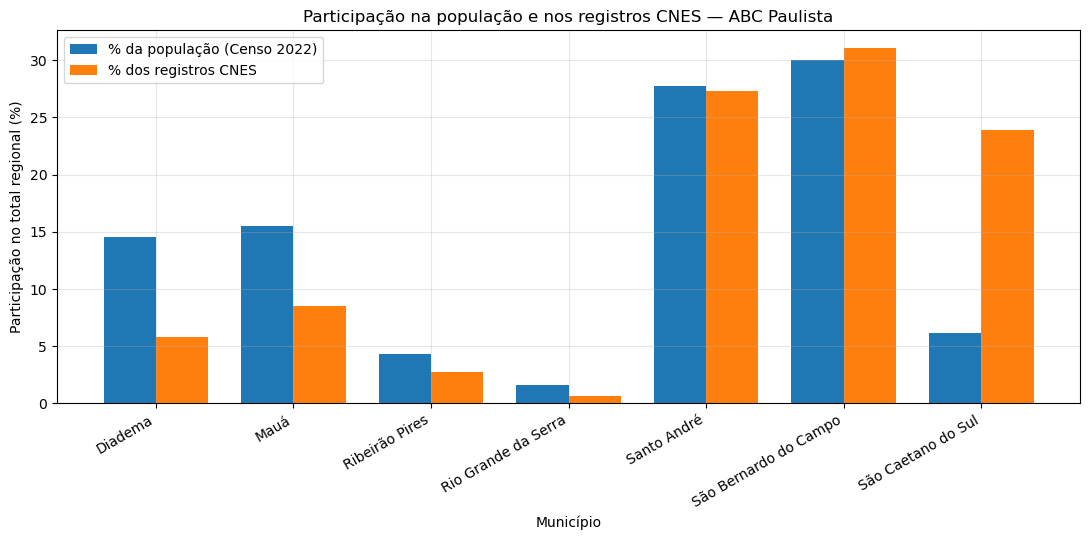

In [16]:
# Gráfico 1 — participação na população x participação nos registros CNES.
posicoes = np.arange(len(base_distribuicao))
largura = 0.38

plt.figure(figsize=(11, 5.5))
plt.bar(posicoes - largura / 2, base_distribuicao["participacao_populacao_pct"], width=largura,
        label="% da população (Censo 2022)")
plt.bar(posicoes + largura / 2, base_distribuicao["participacao_registros_cnes_pct"], width=largura,
        label="% dos registros CNES")
plt.title("Participação na população e nos registros CNES — ABC Paulista")
plt.xlabel("Município")
plt.ylabel("Participação no total regional (%)")
plt.xticks(posicoes, base_distribuicao["municipio"], rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretação do gráfico 1:** a barra de registros supera a de população apenas em São Bernardo do Campo (levemente) e, de forma muito acentuada, em São Caetano do Sul (23,9% dos registros contra 6,1% da população). Em Diadema, Mauá, Ribeirão Pires e Rio Grande da Serra, a fatia de registros é menor que a fatia populacional. Santo André é praticamente proporcional.

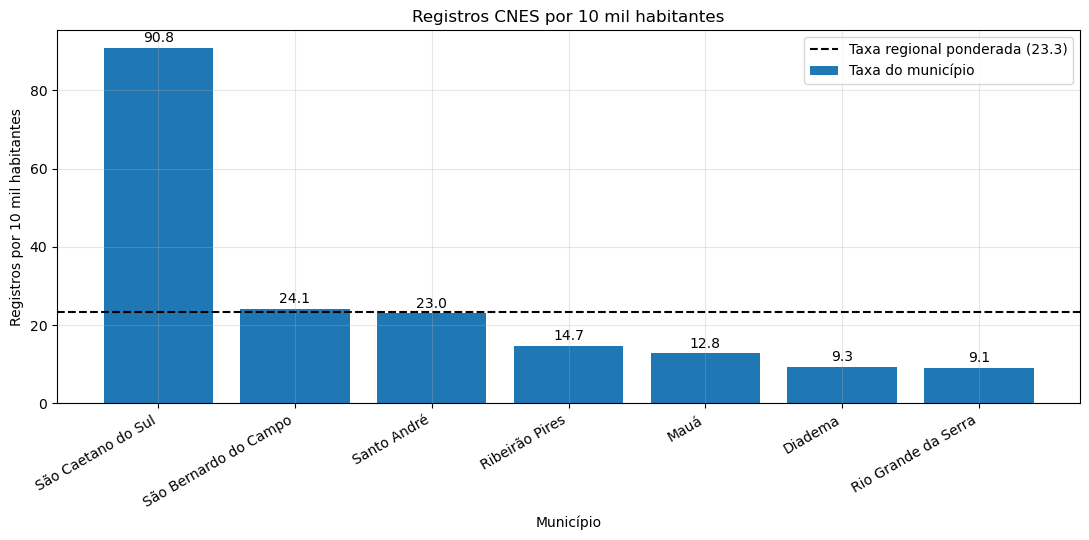

In [17]:
# Gráfico 2 — registros CNES por 10 mil habitantes, com a taxa regional ponderada.
ordenado = base_municipal.sort_values("registros_cnes_por_10mil_hab", ascending=False)

plt.figure(figsize=(11, 5.5))
barras = plt.bar(ordenado["municipio"], ordenado["registros_cnes_por_10mil_hab"], label="Taxa do município")
plt.bar_label(barras, fmt="%.1f", padding=2)
plt.axhline(taxa_regional_ponderada, color="black", linestyle="--",
            label=f"Taxa regional ponderada ({taxa_regional_ponderada:.1f})")
plt.title("Registros CNES por 10 mil habitantes")
plt.xlabel("Município")
plt.ylabel("Registros por 10 mil habitantes")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretação do gráfico 2:** somente São Caetano do Sul (90,8), São Bernardo do Campo (24,1) e Santo André (23,0) ficam acima ou próximos da taxa regional (23,3). Os outros quatro municípios têm taxas entre 9 e 15, ou seja, bem abaixo. A distância entre São Caetano do Sul e os demais é o que mais chama atenção, e por isso é um ponto a investigar (não evidência de melhor acesso).

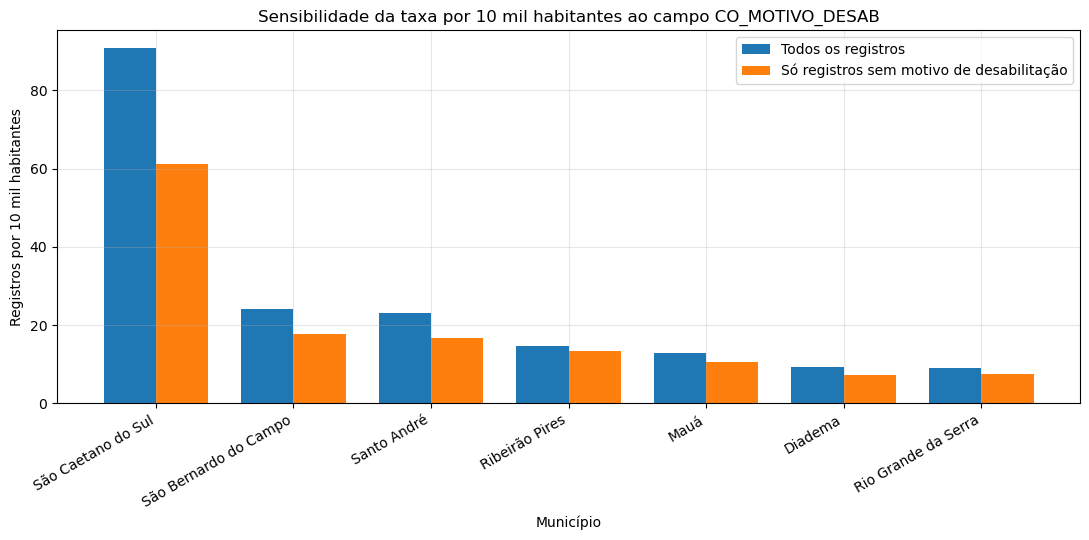

In [18]:
# Gráfico 3 — sensibilidade: todos os registros x só registros sem motivo de desabilitação.
ordem = sensibilidade.sort_values("taxa_todos_por_10mil", ascending=False)
posicoes = np.arange(len(ordem))

plt.figure(figsize=(11, 5.5))
plt.bar(posicoes - largura / 2, ordem["taxa_todos_por_10mil"], width=largura, label="Todos os registros")
plt.bar(posicoes + largura / 2, ordem["taxa_sem_motivo_por_10mil"], width=largura,
        label="Só registros sem motivo de desabilitação")
plt.title("Sensibilidade da taxa por 10 mil habitantes ao campo CO_MOTIVO_DESAB")
plt.xlabel("Município")
plt.ylabel("Registros por 10 mil habitantes")
plt.xticks(posicoes, ordem["municipio"], rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretação do gráfico 3:** todas as barras diminuem ao excluir os registros com motivo preenchido, mas o desenho geral é o mesmo: São Caetano do Sul segue isolado no topo (61,3), seguido por São Bernardo do Campo e Santo André. Ou seja, a desigualdade de distribuição **não é um artefato** desses registros.

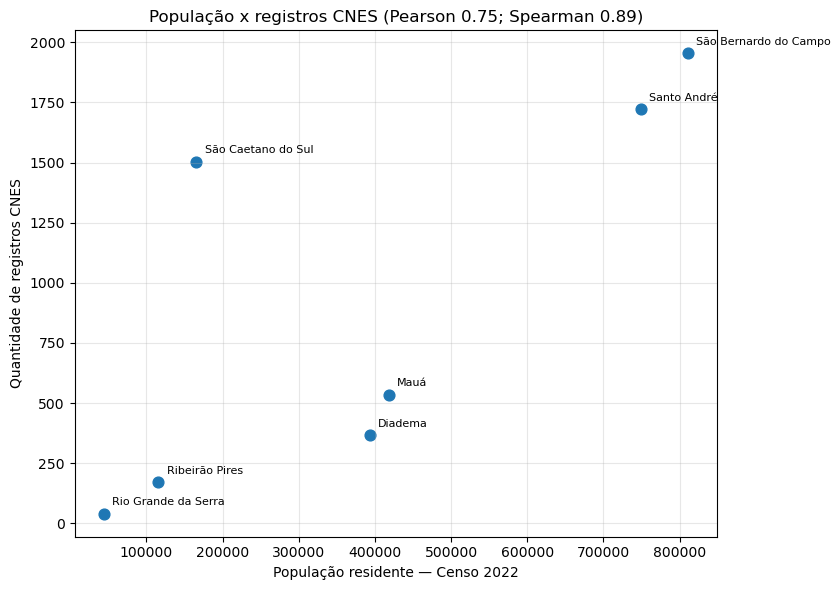

In [19]:
# Gráfico 4 — população x registros CNES, com correlações.
plt.figure(figsize=(8.5, 6))
plt.scatter(base_municipal["populacao_2022"], base_municipal["quantidade_registros"], s=60)
for _, linha in base_municipal.iterrows():
    plt.annotate(linha["municipio"], (linha["populacao_2022"], linha["quantidade_registros"]),
                 xytext=(6, 6), textcoords="offset points", fontsize=8)
plt.title(f"População x registros CNES (Pearson {correlacao_pearson:.2f}; Spearman {correlacao_spearman:.2f})")
plt.xlabel("População residente — Censo 2022")
plt.ylabel("Quantidade de registros CNES")
plt.tight_layout()
plt.show()

**Interpretação do gráfico 4:** os municípios maiores tendem a ter mais registros, o que explica a correlação positiva. São Caetano do Sul destaca-se porque tem cerca de 165 mil habitantes e 1.504 registros, mais do que Mauá e Diadema juntos, que têm mais de 800 mil habitantes e 901 registros.

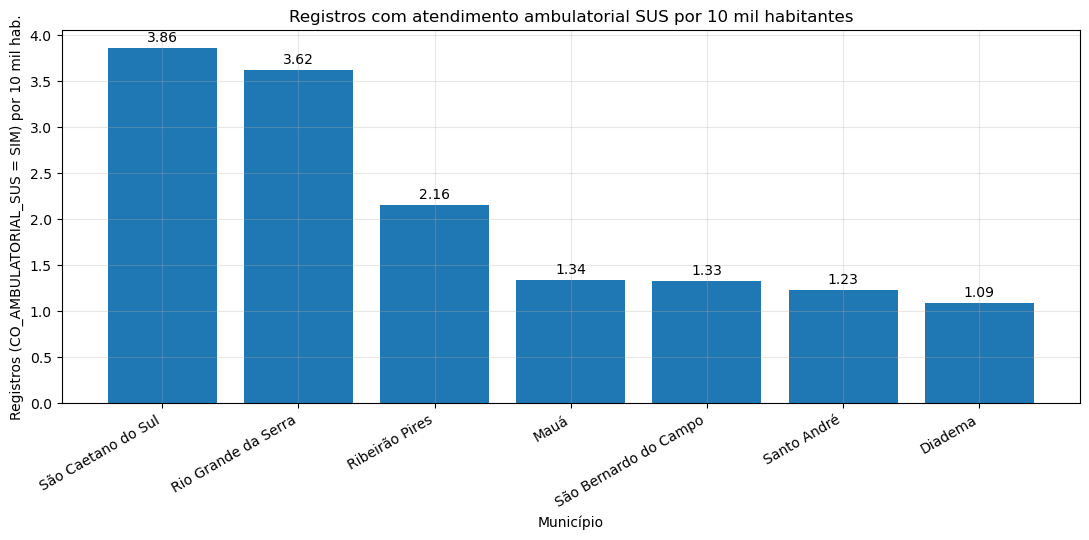

In [20]:
# Gráfico 5 — registros com atendimento ambulatorial SUS por 10 mil habitantes.
ordem_sus = indicador_ambulatorial_sus.sort_values("registros_ambulatoriais_sus_por_10mil_hab", ascending=False)

plt.figure(figsize=(11, 5.5))
barras = plt.bar(ordem_sus["municipio"], ordem_sus["registros_ambulatoriais_sus_por_10mil_hab"])
plt.bar_label(barras, fmt="%.2f", padding=2)
plt.title("Registros com atendimento ambulatorial SUS por 10 mil habitantes")
plt.xlabel("Município")
plt.ylabel("Registros (CO_AMBULATORIAL_SUS = SIM) por 10 mil hab.")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Interpretação do gráfico 5:** o padrão é diferente do total de registros. São Caetano do Sul (3,86) e Rio Grande da Serra (3,62) têm as maiores taxas, e Ribeirão Pires (2,16) vem em seguida. Os outros quatro municípios ficam entre 1,09 e 1,34. Como o campo cobre só atendimento **ambulatorial** SUS cadastrado, não se deve ler este gráfico como medida do atendimento SUS como um todo.

## 13. Conclusões e conexão com a solução

### Situação das hipóteses

| Hipótese | Situação | Evidência |
|---|---|---|
| **H1** — a quantidade de registros varia entre municípios | **Sustentada** | De 40 a 1.954 registros (seção 8) |
| **H2** — a quantidade por habitante difere entre municípios | **Sustentada** | De 9,06 a 90,79 por 10 mil (razão de ~10x); mantém-se ao excluir registros com motivo de desabilitação (seção 10) |
| **H3** — há associação entre população e registros | **Indício exploratório** | Spearman 0,893 (p ≈ 0,007); Pearson 0,748 (p ≈ 0,053); sem São Caetano do Sul, 0,956 e 1,0 (seção 11). Com n = 7, não é conclusivo nem causal |
| **H4** — há relação entre disponibilidade e produção de serviços | **Não testada** | Esta análise não integra dados de produção assistencial |

### Indicadores obtidos

- **6.290** registros CNES nos 7 municípios (2.696.530 habitantes): taxa regional ponderada de **23,33** por 10 mil habitantes (média simples 26,25; mediana 14,71);
- **São Caetano do Sul**: 90,79 por 10 mil, único *outlier* pelo IQR, com **23,9%** dos registros e **6,1%** da população;
- **Menores taxas**: Rio Grande da Serra (9,06) e Diadema (9,31);
- **404** registros (6,4%) com atendimento ambulatorial SUS, e **1.663** (26,4%) com motivo de desabilitação preenchido.

### O que os resultados significam para a solução (Saúde em Foco)

- **Sustentam** a necessidade da solução: a distribuição cadastral difere muito entre municípios de portes distintos, e essa diferença não é visível a quem olha apenas totais.
- **Ajustam** o escopo: contar estabelecimentos não diz se a população é bem atendida. São Caetano do Sul pode, por exemplo, atender moradores de outros municípios, e isso é uma **hipótese**, não um resultado desta análise. Por isso a plataforma deve **integrar dados de produção ambulatorial e de capacidade instalada** (como leitos e serviços), em vez de se apoiar só no cadastro.
- **Indicam prioridades de investigação** (e não de intervenção): os quatro municípios com menor taxa e a explicação do caso de São Caetano do Sul.

### Resposta à pergunta de pesquisa

Os dados mostram diferenças marcantes na distribuição cadastral dos estabelecimentos de saúde entre os municípios do ABC Paulista, inclusive em relação à população, e essas diferenças resistem a um filtro de situação cadastral. Isso sinaliza possíveis desigualdades territoriais que merecem investigação, mas **não é suficiente, isoladamente, para afirmar desigualdade de acesso ou de qualidade**.

## 14. Exportação dos indicadores

Salva as tabelas tratadas em `dados/tratados/`, usadas na proposta executiva e no painel Streamlit.

In [21]:
arquivos_exportados = {
    "base_municipal_saude_em_foco.csv": (base_municipal, False),
    "indicador_esfera_administrativa.csv": (indicador_esfera, False),
    "indicador_ambulatorial_sus.csv": (indicador_ambulatorial_sus, False),
    "distribuicao_populacao_registros_cnes.csv": (base_distribuicao, False),
    "estatistica_descritiva.csv": (estatistica_descritiva, True),
    "sensibilidade_situacao_cadastral.csv": (sensibilidade, False),
    "correlacoes_populacao_registros.csv": (correlacoes, False),
}
for nome, (tabela, com_indice) in arquivos_exportados.items():
    tabela.to_csv(PASTA_TRATADOS / nome, index=com_indice, encoding="utf-8-sig")

print("Arquivos em", PASTA_TRATADOS, ":")
for arquivo in sorted(PASTA_TRATADOS.glob("*.csv")):
    print(" -", arquivo.name)

Arquivos em dados\tratados :
 - base_municipal_saude_em_foco.csv
 - cnes_abc_minimizado.csv
 - cnes_estabelecimentos_abc.csv
 - correlacoes_populacao_registros.csv
 - distribuicao_populacao_registros_cnes.csv
 - estatistica_descritiva.csv
 - indicador_ambulatorial_sus.csv
 - indicador_esfera_administrativa.csv
 - populacao_abc_censo_2022.csv
 - sensibilidade_situacao_cadastral.csv


## 15. Limitações e uso responsável dos dados

### Limitações das bases e da análise

1. **Registro não é capacidade.** A contagem de registros CNES não mede capacidade instalada, qualidade, acesso nem suficiência dos serviços.
2. **Públicos e privados juntos.** O CNES cadastra estabelecimentos públicos e privados, com ou sem atendimento SUS. Os 6.290 registros **não** são tratados como "rede pública". A esfera administrativa (`MUNICIPAL`/`ESTADUAL`) e a natureza jurídica (`CO_NATUREZA_JUR`, não traduzida aqui) não foram usadas para classificar a rede.
3. **`CO_AMBULATORIAL_SUS` é específico.** Refere-se apenas a atendimento ambulatorial SUS.
4. **Situação cadastral não confirmada.** `CO_MOTIVO_DESAB` está preenchido em 1.663 registros. Como não confirmamos o significado no dicionário, os indicadores descrevem **registros cadastrados**, e a seção 10 mostra que as conclusões resistem a esse filtro.
5. **Períodos diferentes.** O Censo é de 2022 e o arquivo CNES foi gerado em 14/11/2026, **sem informação de competência do cadastro** no arquivo. A população pode ter mudado no intervalo.
6. **Sem dimensão temporal.** Há uma única fotografia do CNES, então não é possível dizer como a situação evolui.
7. **Escala municipal.** A análise não permite conclusões por bairro; municípios com boa média podem esconder desigualdades internas.
8. **Amostra pequena.** Com n = 7, correlações e valores-p são exploratórios, e correlação não implica causalidade.
9. **População residente.** O denominador é a população que mora no município, não a que usa seus serviços (quem trabalha ou se trata em outro município).

### Possíveis vieses que podem excluir grupos

- **Cadastro formal.** O CNES só enxerga serviços formalmente cadastrados. Atendimentos informais, comunitários ou itinerantes não aparecem, o que tende a invisibilizar territórios mais vulneráveis.
- **Contagem por unidade.** Um registro pesa o mesmo para um consultório e para um hospital; municípios com muitos consultórios podem parecer "bem servidos" sem que isso reflita acesso real.
- **Quem não está no Censo.** Pessoas sem domicílio fixo ou em ocupações irregulares podem estar sub-representadas no denominador.
- **Uso na plataforma.** Os indicadores devem ser apresentados como **distribuição cadastral**, e não como ranking de qualidade ou de "culpa" dos municípios.

### Privacidade e LGPD

- A análise usa **dados públicos e agregados por município**. Não há dados de pacientes nem dados pessoais sensíveis.
- Como o CNES inclui pessoas físicas e empresários individuais como estabelecimentos, os campos de identificação (CNPJ, razão social, nome fantasia, telefone, e-mail, endereço, CEP e coordenadas) foram **removidos** antes de salvar qualquer arquivo (seção 6), seguindo o princípio da minimização (LGPD, art. 6º, III).
- O arquivo bruto **não deve ser compartilhado** nem versionado em repositórios públicos. Somente o CSV minimizado acompanha a entrega.
- Em uma evolução da solução com dados de produção ou de pacientes, será necessário **anonimizar** os dados, definir base legal para o tratamento e agregar os resultados em níveis que impeçam a reidentificação.

## 16. Referências

- **Portal de Dados Abertos do SUS — CNES Estabelecimentos:** https://dadosabertos.saude.gov.br/dataset/cnes-cadastro-nacional-de-estabelecimentos-de-saude
- **Wiki CNES — Portal e filtros de consulta:** https://wiki.saude.gov.br/cnes/index.php/Portal_CNES
- **Wiki CNES — Download da base e dicionário de dados:** https://wiki.saude.gov.br/cnes/index.php/Categoria:Consumo_de_informa%C3%A7%C3%B5es_da_Base_Nacional_do_CNES_via_webservice_e_Download_da_Base_de_Dados
- **IBGE/SIDRA — Tabela 4709 (Censo 2022):** https://sidra.ibge.gov.br/tabela/4709
- **LGPD — Lei nº 13.709/2018:** https://www.planalto.gov.br/ccivil_03/_ato2015-2018/2018/lei/l13709.htm